In [1]:
import pandas as pd 
import numpy as np 

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hrishitpatil/flight-data-2024")

print("Path to dataset files:", path)

Path to dataset files: /Users/megantimmes/.cache/kagglehub/datasets/hrishitpatil/flight-data-2024/versions/2


In [3]:
import os

csv_path = os.path.join(path, "flight_data_2024.csv")
parquet_path = "data/flight_data_2024.parquet"

dtypes = {
    # low-cardinality text -> category (big memory savings)
    "op_unique_carrier": "category", "origin": "category", "dest": "category",
    "origin_city_name": "category", "dest_city_name": "category",
    "origin_state_nm": "category", "dest_state_nm": "category",
    "cancellation_code": "category",
    # small integers
    "year": "int16", "month": "int8", "day_of_month": "int8", "day_of_week": "int8",
    "crs_dep_time": "int16", "crs_arr_time": "int16",
    "cancelled": "int8", "diverted": "int8",
    "carrier_delay": "int32", "weather_delay": "int32", "nas_delay": "int32",
    "security_delay": "int32", "late_aircraft_delay": "int32",
    # floats with NaNs -> float32
    **{c: "float32" for c in [
        "op_carrier_fl_num", "dep_time", "dep_delay", "taxi_out", "wheels_off",
        "wheels_on", "taxi_in", "arr_time", "arr_delay", "crs_elapsed_time",
        "actual_elapsed_time", "air_time", "distance"]},
}

# Read category columns as plain strings first, then convert after loading.
# (pandas reads in chunks; mostly-empty columns like cancellation_code get
# mismatched category types across chunks otherwise.)
cat_cols = [k for k, v in dtypes.items() if v == "category"]
read_dtypes = {k: ("str" if v == "category" else v) for k, v in dtypes.items()}

if os.path.exists(parquet_path):
    df = pd.read_parquet(parquet_path)          # fast path (seconds)
else:
    df = pd.read_csv(csv_path, dtype=read_dtypes, parse_dates=["fl_date"])
    df[cat_cols] = df[cat_cols].astype("category")
    os.makedirs("data", exist_ok=True)
    df.to_parquet(parquet_path, index=False)    # one-time conversion

print(df.shape)
df.info(memory_usage="deep")

(7079081, 35)
<class 'pandas.DataFrame'>
RangeIndex: 7079081 entries, 0 to 7079080
Data columns (total 35 columns):
 #   Column               Dtype         
---  ------               -----         
 0   year                 int16         
 1   month                int8          
 2   day_of_month         int8          
 3   day_of_week          int8          
 4   fl_date              datetime64[us]
 5   op_unique_carrier    category      
 6   op_carrier_fl_num    float32       
 7   origin               category      
 8   origin_city_name     category      
 9   origin_state_nm      category      
 10  dest                 category      
 11  dest_city_name       category      
 12  dest_state_nm        category      
 13  crs_dep_time         int16         
 14  dep_time             float32       
 15  dep_delay            float32       
 16  taxi_out             float32       
 17  wheels_off           float32       
 18  wheels_on            float32       
 19  taxi_in           

In [4]:
df.head()

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288.0,0,0,0,0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,0,111.0,76.0,51.0,288.0,0,0,0,0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,0,79.0,70.0,45.0,237.0,0,0,0,0,0


In [5]:
delay_columns = ['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']


In [6]:
# is_delayed is the target for the first model. I removed the types of delay from this dataset 
# I then looked at the percentage of delays from the entire dataset
df["is_delayed"] = (df[delay_columns] > 0).any(axis=1).astype("int8")

pct_delayed = df["is_delayed"].mean() * 100
print(f"Delayed flights: {df['is_delayed'].sum():,} of {len(df):,} ({pct_delayed:.2f}%)")

Delayed flights: 1,449,970 of 7,079,081 (20.48%)


In [7]:
#dropped the other delay columns
df = df.drop(delay_columns, axis=1)

In [8]:
df.head()

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,arr_time,arr_delay,cancelled,cancellation_code,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,is_delayed
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,1449.0,-19.0,0,NaN,0,136.0,122.0,84.0,509.0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,1255.0,-30.0,0,NaN,0,130.0,114.0,88.0,622.0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,1541.0,-20.0,0,NaN,0,106.0,90.0,61.0,288.0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,1759.0,-42.0,0,NaN,0,111.0,76.0,51.0,288.0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,1020.0,-14.0,0,NaN,0,79.0,70.0,45.0,237.0,0


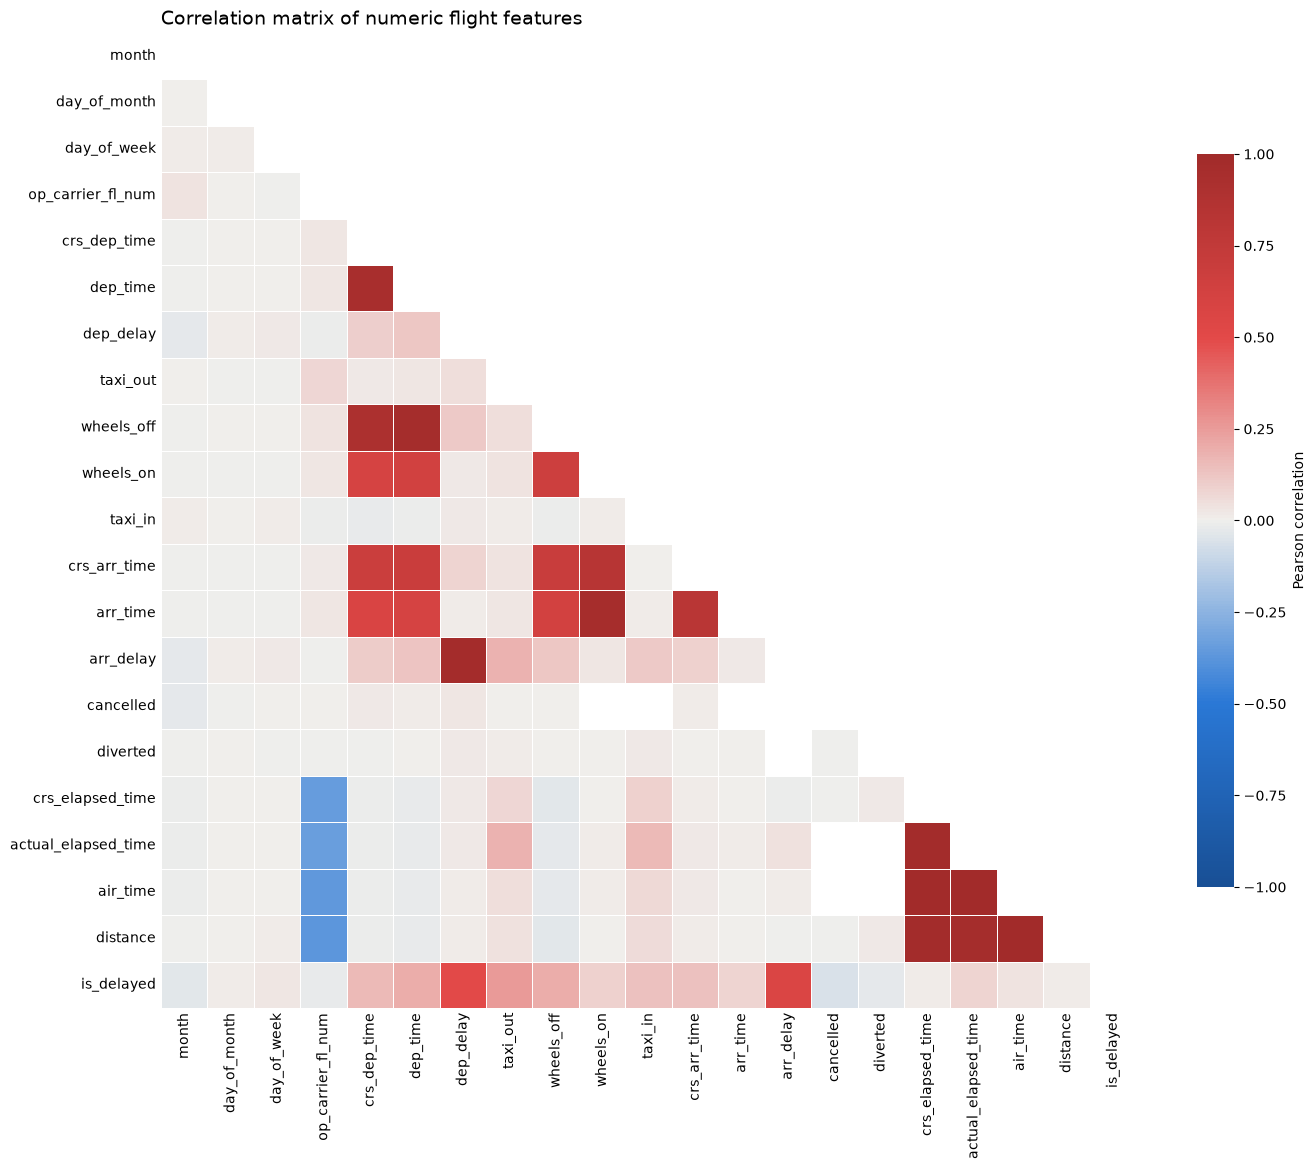

arr_delay              0.570
dep_delay              0.502
taxi_out               0.255
dep_time               0.202
wheels_off             0.199
crs_dep_time           0.159
taxi_in                0.136
crs_arr_time           0.134
wheels_on              0.090
actual_elapsed_time    0.082
arr_time               0.080
cancelled             -0.060
air_time               0.036
month                 -0.034
day_of_week            0.027
diverted              -0.025
op_carrier_fl_num     -0.017
distance               0.015
crs_elapsed_time       0.014
day_of_month           0.010
Name: is_delayed, dtype: float64

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Numeric columns only; drop constants (e.g. year is always 2024)
num = df.select_dtypes("number")
num = num.loc[:, num.nunique() > 1]

corr = num.corr()  # Pearson; use method="spearman" for rank correlation

# Diverging map: blue (negative) -> neutral gray (0) -> red (positive)
cmap = LinearSegmentedColormap.from_list(
    "div", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#a12b2a"]
)

mask = np.triu(np.ones_like(corr, dtype=bool))  # show lower triangle only
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5, linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax,
)
ax.set_title("Correlation matrix of numeric flight features", loc="left", fontsize=14)
ax.tick_params(length=0)
plt.tight_layout()
plt.show()

# Table view: features most correlated with the target
corr["is_delayed"].drop("is_delayed").sort_values(key=abs, ascending=False).round(3)

## EDA helpers

In [10]:
# ---- EDA helpers: delay rate by group + a consistent bar-chart style ----
import matplotlib.pyplot as plt

BAR = "#2a78d6"     # single-series bar color
REF = "#52514e"     # reference line / secondary text
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.titlesize": 13, "xtick.color": REF, "ytick.color": REF,
})

def delay_rate(data, col, observed=True):
    """Delay rate (%) and flight count for each value of `col`."""
    out = (data.groupby(col, observed=observed)["is_delayed"]
               .agg(pct_delayed="mean", flights="size"))
    out["pct_delayed"] *= 100
    return out

def plot_rate(table, title, horizontal=False, overall=None, figsize=(10, 4.5)):
    """Bar chart of pct_delayed with a dashed line at the overall rate."""
    fig, ax = plt.subplots(figsize=figsize)
    labels = table.index.astype(str)
    if horizontal:
        ax.barh(labels, table["pct_delayed"], color=BAR, height=0.7)
        ax.invert_yaxis()
        ax.grid(axis="y", visible=False)
        if overall is not None:
            ax.axvline(overall, color=REF, ls="--", lw=1)
            ax.text(overall, -0.9, f" overall {overall:.1f}%", color=REF, fontsize=9)
        ax.set_xlabel("% of flights delayed (arrived 15+ min late)")
    else:
        ax.bar(labels, table["pct_delayed"], color=BAR, width=0.7)
        ax.grid(axis="x", visible=False)
        if overall is not None:
            ax.axhline(overall, color=REF, ls="--", lw=1)
            ax.text(1.005, overall, f"overall\n{overall:.1f}%", color=REF, fontsize=9,
                    ha="left", va="center", transform=ax.get_yaxis_transform())
        ax.set_ylabel("% of flights delayed")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

## Step 1: Modeling population

In [11]:
# ---- Step 1: modeling population ----
# Cancelled and diverted flights never "arrive late", so they'd be counted as on time.
# Keep df as-is and model only flights that actually flew and landed at their destination.
print(f"Cancelled: {df['cancelled'].sum():,}  ({df['cancelled'].mean()*100:.2f}%)")
print(f"Diverted:  {df['diverted'].sum():,}  ({df['diverted'].mean()*100:.2f}%)")

flown = df[(df["cancelled"] == 0) & (df["diverted"] == 0)].copy()
overall = flown["is_delayed"].mean() * 100
print(f"\nFlights that flew: {len(flown):,}")
print(f"Delay rate among flights that flew: {overall:.2f}%")

Cancelled: 96,315  (1.36%)
Diverted:  17,499  (0.25%)

Flights that flew: 6,965,267
Delay rate among flights that flew: 20.82%


## Step 2: Carrier and airport

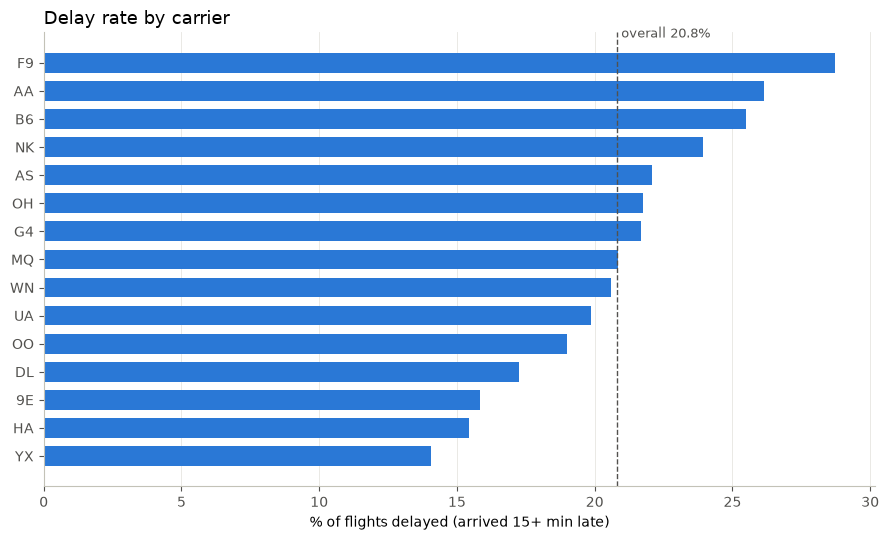

,pct_delayed,flights
op_unique_carrier,,
F9,28.7,203482
AA,26.1,966116
B6,25.5,235683
NK,23.9,255633
AS,22.1,240323
OH,21.8,223673
G4,21.7,114882
MQ,20.9,275317
WN,20.6,1404597


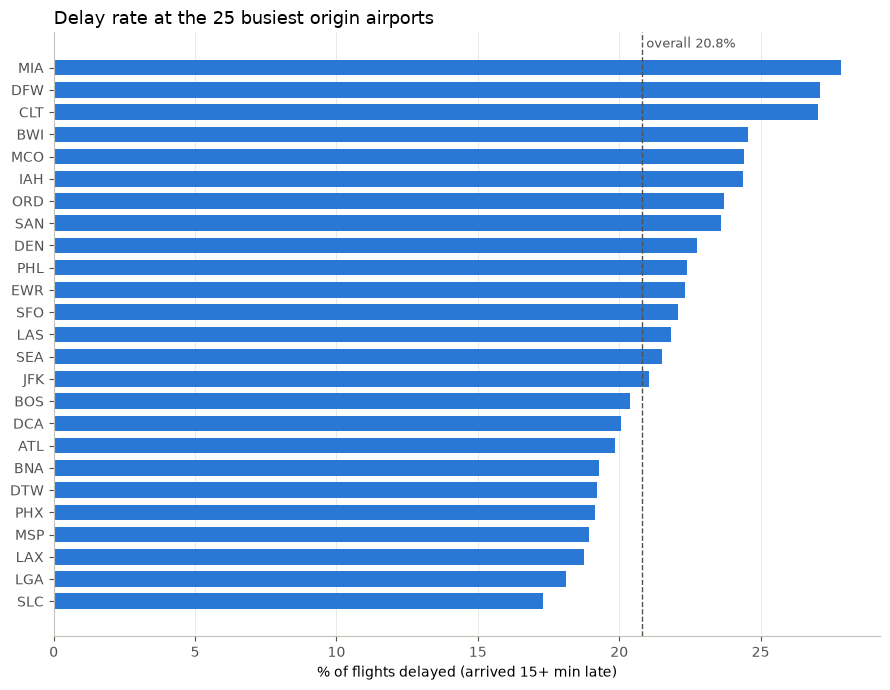

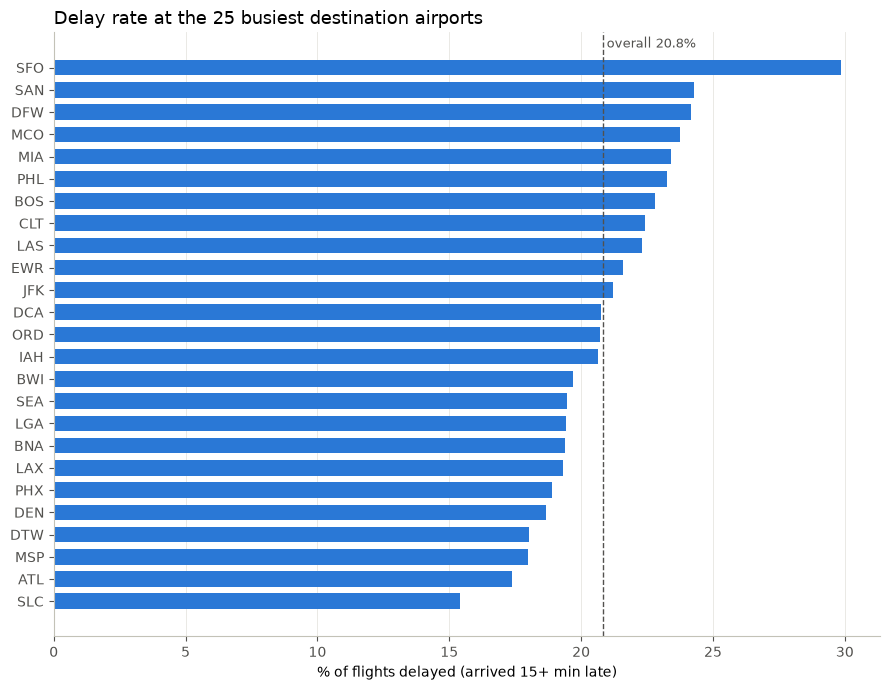

348 origin airports
  with <    100 flights: 7
  with <  1,000 flights: 114
  with < 10,000 flights: 247


In [12]:
# ---- Step 2: delay rate by carrier and airport ----
carrier = delay_rate(flown, "op_unique_carrier").sort_values("pct_delayed", ascending=False)
plot_rate(carrier, "Delay rate by carrier", horizontal=True, overall=overall, figsize=(9, 5.5))
display(carrier.round(1))

TOP_N = 25
for col, name in [("origin", "origin"), ("dest", "destination")]:
    t = delay_rate(flown, col)
    top = t.nlargest(TOP_N, "flights").sort_values("pct_delayed", ascending=False)
    plot_rate(top, f"Delay rate at the {TOP_N} busiest {name} airports",
              horizontal=True, overall=overall, figsize=(9, 7))

# How many airports are small? (matters for how you encode origin/dest)
counts = delay_rate(flown, "origin")["flights"]
print(f"{len(counts)} origin airports")
for n in [100, 1_000, 10_000]:
    print(f"  with < {n:>6,} flights: {(counts < n).sum()}")

## Step 3: Timing

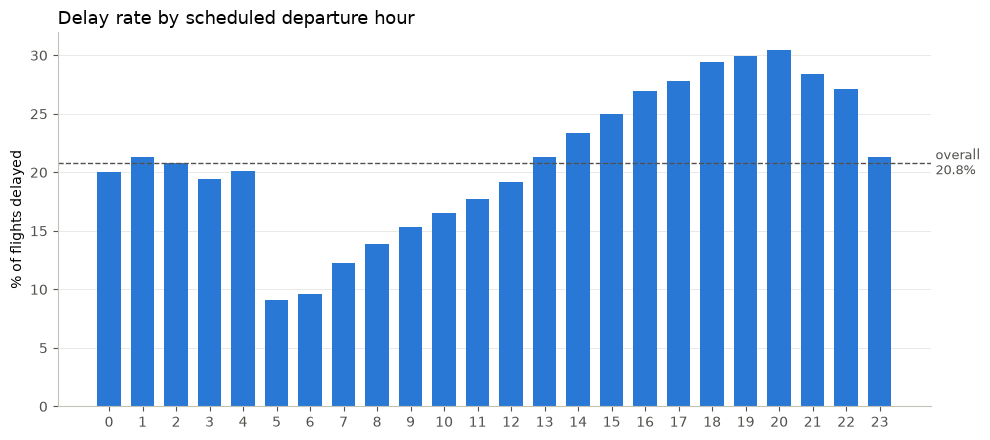

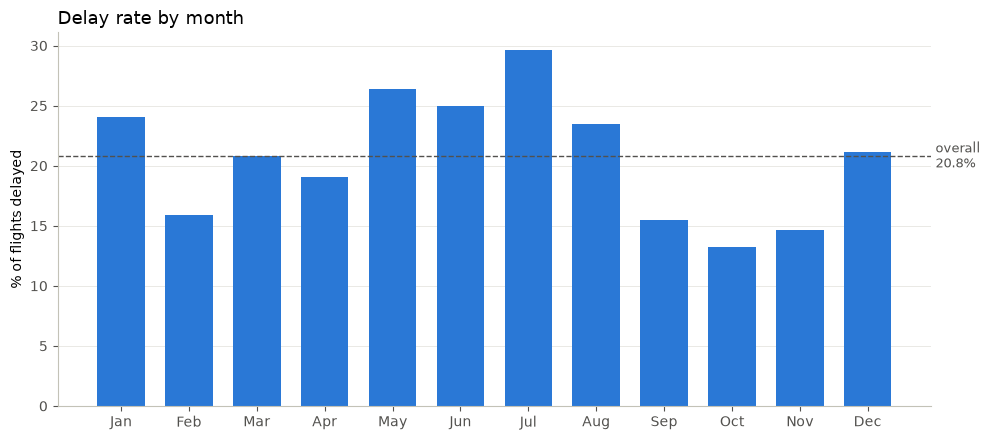

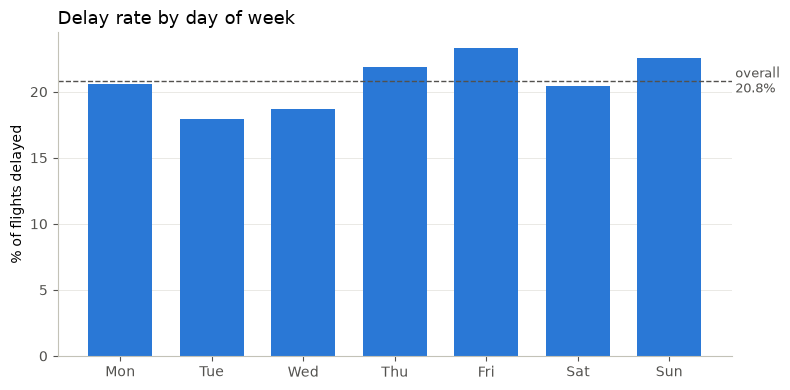

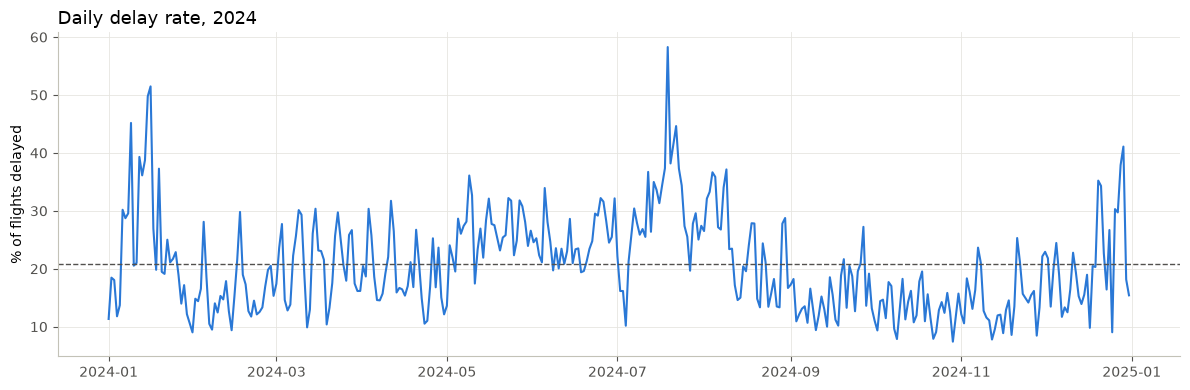

Worst days:


,pct_delayed
fl_date,
2024-07-19,58.3
2024-01-16,51.5
2024-01-15,49.8
2024-01-09,45.2
2024-07-22,44.6
2024-07-21,41.5
2024-12-29,41.1
2024-01-12,39.3
2024-01-14,38.7


In [13]:
# ---- Step 3: timing ----
# crs_dep_time / crs_arr_time are HHMM numbers (1430 = 2:30 pm); 2400 means midnight
for c in ["crs_dep_time", "crs_arr_time"]:
    t = flown[c] % 2400
    flown[c.replace("_time", "_hour")] = (t // 100).astype("int8")
    flown[c.replace("_time", "_min_of_day")] = (t // 100 * 60 + t % 100).astype("int16")

hour = delay_rate(flown, "crs_dep_hour")
plot_rate(hour, "Delay rate by scheduled departure hour", overall=overall)

month = delay_rate(flown, "month")
month.index = pd.to_datetime(month.index, format="%m").strftime("%b")
plot_rate(month, "Delay rate by month", overall=overall)

dow = delay_rate(flown, "day_of_week")   # BTS coding: 1 = Monday ... 7 = Sunday
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plot_rate(dow, "Delay rate by day of week", overall=overall, figsize=(8, 4))

# Daily delay rate across the year (shows storms and holiday peaks)
daily = flown.groupby("fl_date")["is_delayed"].mean() * 100
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.values, color=BAR, lw=1.5)
ax.axhline(overall, color=REF, ls="--", lw=1)
ax.set_ylabel("% of flights delayed")
ax.set_title("Daily delay rate, 2024")
plt.tight_layout()
plt.show()
print("Worst days:")
display(daily.nlargest(10).round(1).to_frame("pct_delayed"))

## Step 4: Distance and duration

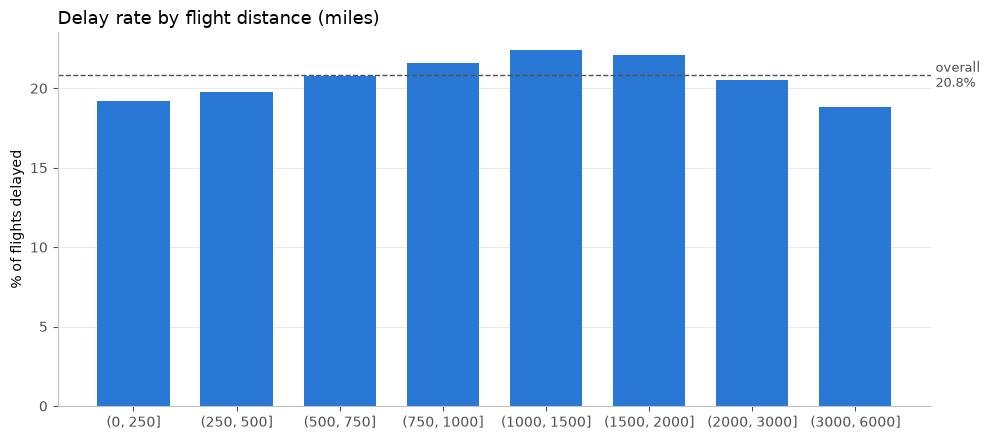

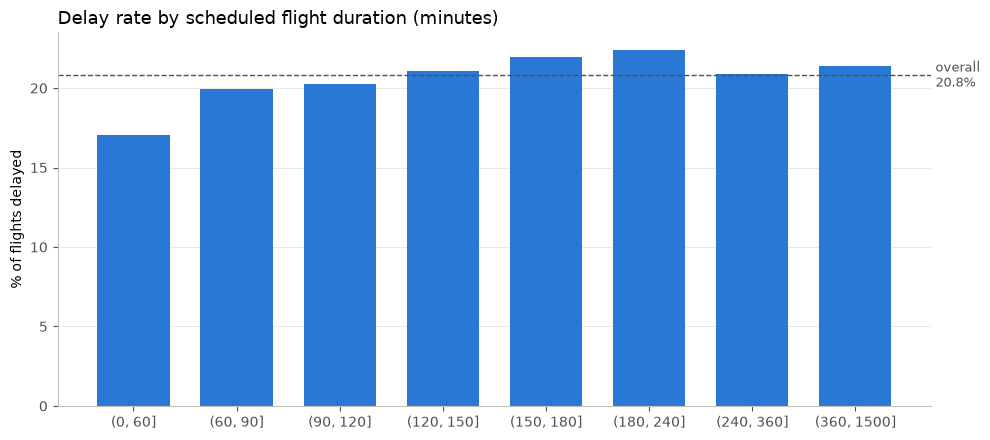

,pct_delayed,flights
distance_bin,,
"(0, 250]",19.2,796222
"(250, 500]",19.7,1603736
"(500, 750]",20.8,1388111
"(750, 1000]",21.6,1146957
"(1000, 1500]",22.4,1131972
"(1500, 2000]",22.1,470101
"(2000, 3000]",20.5,413457
"(3000, 6000]",18.8,14711


In [14]:
# ---- Step 4: distance and scheduled duration (binned, to catch non-linear effects) ----
dist_bins = [0, 250, 500, 750, 1000, 1500, 2000, 3000, 6000]
flown["distance_bin"] = pd.cut(flown["distance"], bins=dist_bins)
plot_rate(delay_rate(flown, "distance_bin"), "Delay rate by flight distance (miles)",
          overall=overall)

dur_bins = [0, 60, 90, 120, 150, 180, 240, 360, 1500]
flown["crs_elapsed_bin"] = pd.cut(flown["crs_elapsed_time"], bins=dur_bins)
plot_rate(delay_rate(flown, "crs_elapsed_bin"),
          "Delay rate by scheduled flight duration (minutes)", overall=overall)

display(delay_rate(flown, "distance_bin").round(1))

## Step 5: Data quality

In [15]:
# ---- Step 5: data quality ----
missing = flown.isna().mean().mul(100).round(2)
print("Missing values (% of flown flights), columns with any:")
# cancellation_code is 100% missing here (no flown flight was cancelled) - drop it
display(missing[missing > 0].sort_values(ascending=False).to_frame("pct_missing"))

print("Odd values:")
print(f"  crs_elapsed_time <= 0:          {(flown['crs_elapsed_time'] <= 0).sum():,}")
print(f"  actual_elapsed_time <= 0:       {(flown['actual_elapsed_time'] <= 0).sum():,}")
print(f"  crs_dep_time == 2400:           {(flown['crs_dep_time'] == 2400).sum():,}")
print(f"  air_time > actual_elapsed_time: {(flown['air_time'] > flown['actual_elapsed_time']).sum():,}")
# (Negative crs_elapsed_time exists in df but only among cancelled/diverted flights.)

key = ["fl_date", "op_unique_carrier", "op_carrier_fl_num", "origin", "dest", "crs_dep_time"]
print(f"Exact duplicate rows:            {flown.duplicated().sum():,}")
print(f"Duplicate flights (same key):    {flown.duplicated(subset=key).sum():,}")

Missing values (% of flown flights), columns with any:


,pct_missing
cancellation_code,100.0


Odd values:
  crs_elapsed_time <= 0:          0
  actual_elapsed_time <= 0:       0
  crs_dep_time == 2400:           1
  air_time > actual_elapsed_time: 0
Exact duplicate rows:            0
Duplicate flights (same key):    0


In [16]:
#drop columns with data leakage

data_leakage = ['arr_delay', 'dep_delay', 'taxi_out', 'dep_time']
df = df.drop(data_leakage, axis =1)

In [17]:
df.head()

,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,crs_arr_time,arr_time,cancelled,cancellation_code,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,is_delayed
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,1508,1449.0,0,NaN,0,136.0,122.0,84.0,509.0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,1325,1255.0,0,NaN,0,130.0,114.0,88.0,622.0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,1601,1541.0,0,NaN,0,106.0,90.0,61.0,288.0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,1841,1759.0,0,NaN,0,111.0,76.0,51.0,288.0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,1034,1020.0,0,NaN,0,79.0,70.0,45.0,237.0,0


In [18]:
# dropping the fl_date because the info is capturedd from the month, day of month, day of week
# also dropping the year bc it is all the same

df = df.drop(['year', 'fl_date'], axis = 1)

In [19]:
df.head()

,month,day_of_month,day_of_week,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,dest,dest_city_name,...,crs_arr_time,arr_time,cancelled,cancellation_code,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,is_delayed
0,1,1,1,9E,4814.0,JFK,"New York, NY",New York,DTW,"Detroit, MI",...,1508,1449.0,0,NaN,0,136.0,122.0,84.0,509.0,0
1,1,1,1,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,CLE,"Cleveland, OH",...,1325,1255.0,0,NaN,0,130.0,114.0,88.0,622.0,0
2,1,1,1,9E,4817.0,JFK,"New York, NY",New York,RIC,"Richmond, VA",...,1601,1541.0,0,NaN,0,106.0,90.0,61.0,288.0,0
3,1,1,1,9E,4817.0,RIC,"Richmond, VA",Virginia,JFK,"New York, NY",...,1841,1759.0,0,NaN,0,111.0,76.0,51.0,288.0,0
4,1,1,1,9E,4818.0,DTW,"Detroit, MI",Michigan,MKE,"Milwaukee, WI",...,1034,1020.0,0,NaN,0,79.0,70.0,45.0,237.0,0


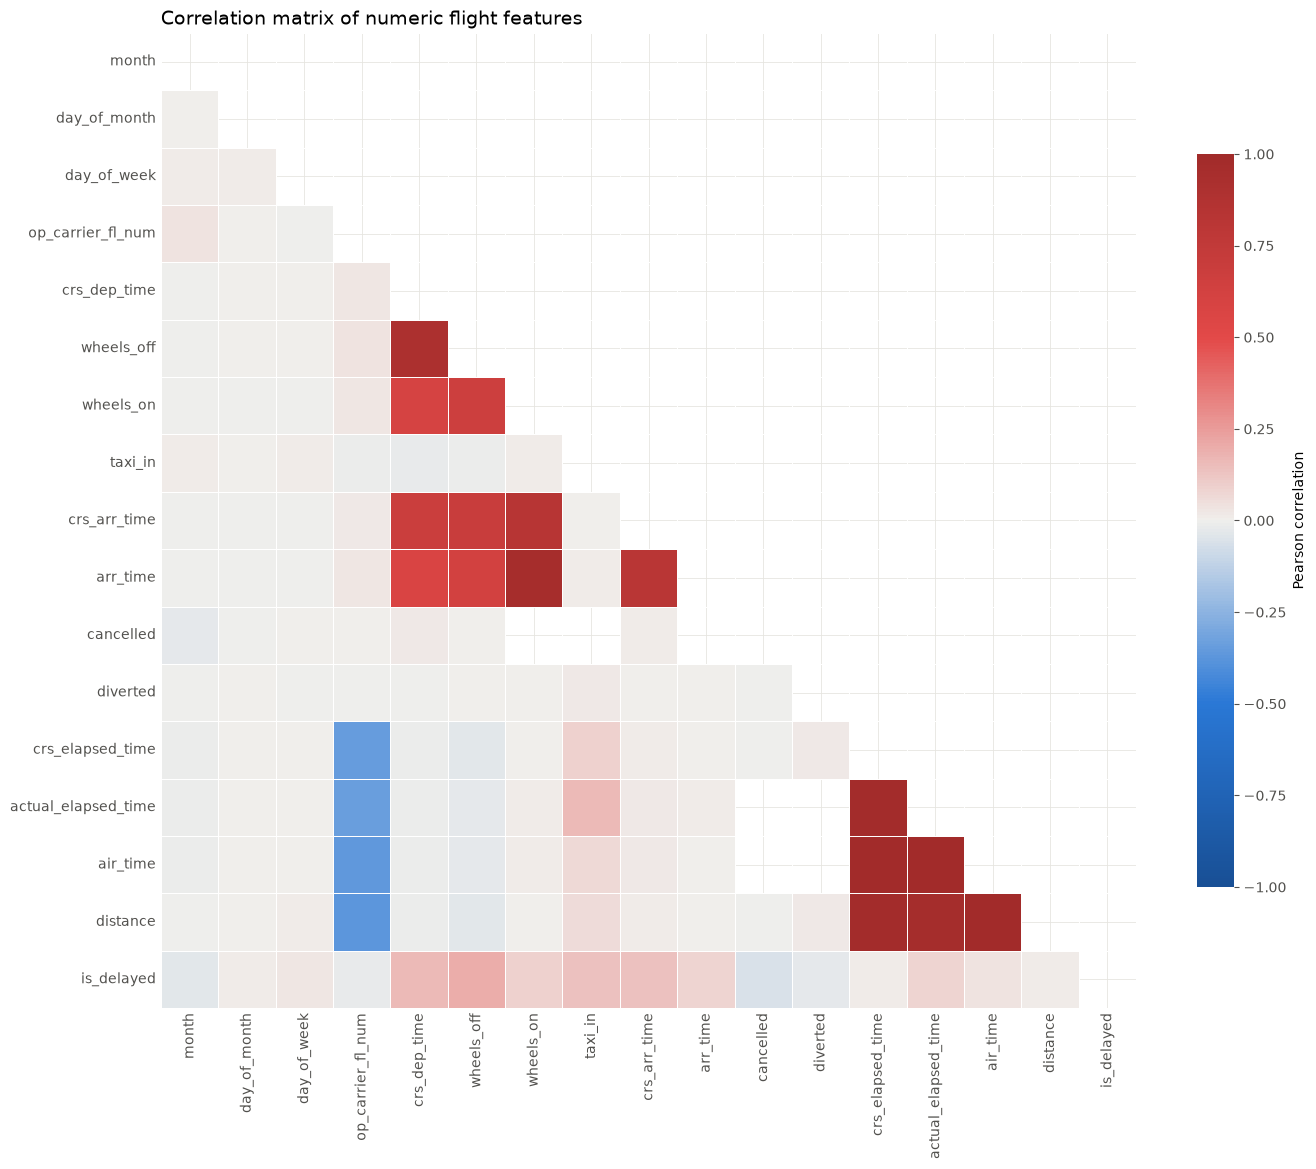

wheels_off             0.199
crs_dep_time           0.159
taxi_in                0.136
crs_arr_time           0.134
wheels_on              0.090
actual_elapsed_time    0.082
arr_time               0.080
cancelled             -0.060
air_time               0.036
month                 -0.034
day_of_week            0.027
diverted              -0.025
op_carrier_fl_num     -0.017
distance               0.015
crs_elapsed_time       0.014
day_of_month           0.010
Name: is_delayed, dtype: float64

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Numeric columns only; drop constants (e.g. year is always 2024)
num = df.select_dtypes("number")
num = num.loc[:, num.nunique() > 1]

corr = num.corr()  # Pearson; use method="spearman" for rank correlation

# Diverging map: blue (negative) -> neutral gray (0) -> red (positive)
cmap = LinearSegmentedColormap.from_list(
    "div", ["#184f95", "#2a78d6", "#f0efec", "#e34948", "#a12b2a"]
)

mask = np.triu(np.ones_like(corr, dtype=bool))  # show lower triangle only
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr, mask=mask, cmap=cmap, vmin=-1, vmax=1, center=0,
    square=True, linewidths=0.5, linecolor="white",
    cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax,
)
ax.set_title("Correlation matrix of numeric flight features", loc="left", fontsize=14)
ax.tick_params(length=0)
plt.tight_layout()
plt.show()

# Table view: features most correlated with the target
corr["is_delayed"].drop("is_delayed").sort_values(key=abs, ascending=False).round(3)

In [21]:
df.shape

(7079081, 25)